# Cap. 4 · Descomposición y suavizamiento exponencial
*Proyecto DAT 262 · Monitor de estrés cambiario y monetario de Bolivia*

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from stress_monitor import data, stationarity as stat, markov as mk, forecasting as fc, gap as gp, simulation as sim, demo
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
m = data.load_monthly(); d = data.load_daily_key()
print("Datos mensuales:", m.index.min().date(), "→", m.index.max().date(), f"({len(m)} meses)")

Datos mensuales: 1989-01-31 → 2026-10-31 (454 meses)


Modelo clásico multiplicativo: $X_t = T_t \cdot S_t \cdot e_t$. La *fuerza estacional* $F_s=\max(0,1-Var(e)/Var(S+e))$ guía si hace falta diferenciar estacionalmente.

Fuerza estacional IPC: 0.04


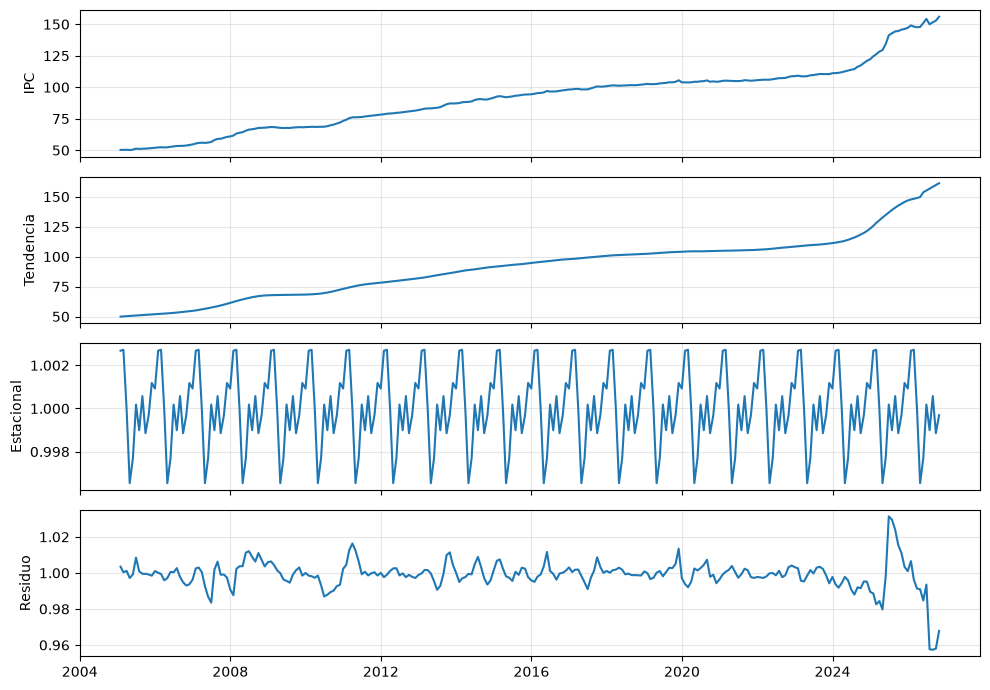

In [2]:
s = m['ipc'][m.index >= '2005']
dec = fc.decompose(s, 'multiplicative')
fig, ax = plt.subplots(4, 1, figsize=(10, 7), sharex=True)
for a, (v, t) in zip(ax, ((dec.observed, 'IPC'), (dec.trend, 'Tendencia'), (dec.seasonal, 'Estacional'), (dec.resid, 'Residuo'))): a.plot(v); a.set_ylabel(t)
plt.tight_layout()
print('Fuerza estacional IPC: %.2f' % fc.seasonal_strength(s))

In [3]:
for c in ['depositos_me', 'base_monetaria', 'rib']: print(c, 'Fs = %.2f' % fc.seasonal_strength(m[c][m.index >= '2005']))

depositos_me Fs = 0.06
base_monetaria Fs = 0.51
rib Fs = 0.03


### Holt-Winters (tendencia amortiguada + estacionalidad) frente al modelo ingenuo, pronóstico a 6 meses

In [4]:
y = fc.log_series(m, 'depositos_me')
train, real = y.iloc[:-6], np.exp(y.iloc[-6:])
hw = np.exp(fc.holt_winters_forecast(train, 6)); naive = pd.Series(np.exp(train.iloc[-1]), index=real.index)
print('MAPE HW      : %.2f%%' % ((hw.values - real.values).__abs__() / real.values).mean().__mul__(100))
print('MAPE ingenuo : %.2f%%' % ((naive.values - real.values).__abs__() / real.values).mean().__mul__(100))
pd.DataFrame({'real': real, 'HW': hw.values, 'ingenuo': naive.values}).round(0)

MAPE HW      : 3.79%
MAPE ingenuo : 3.00%


,real,HW,ingenuo
date,,,
2026-05-31,2815.0,2616.0,2635.0
2026-06-30,2784.0,2599.0,2635.0
2026-07-31,2713.0,2588.0,2635.0
2026-08-31,2647.0,2574.0,2635.0
2026-09-30,2616.0,2577.0,2635.0
2026-10-31,2578.0,2583.0,2635.0
